# Week 4: Transfer Learning, BERT (Homework)

## Question Search Engine

Embeddings are a good source of information for solving various tasks. For example, we can classify texts or find similar documents using their representations. We already know about word2vec, GloVe and fasttext, but they don't use context information from given text (only from contexts of source data).

For today we will use full power of context-aware embeddings to find text duplicates!

__Warning:__ this task assumes you have seen `seminar.ipynb`!

## Rules

This notebook is checked automatically by **ThetaGrader (TG)**.

- Keep every `### Task N` heading intact -- TG uses it as a marker to locate tasks. Do not remove, rename, renumber, or duplicate these headings.
- Write your solution in the cell(s) reserved for it, directly below the corresponding task statement. Do not move a solution to a different place in the notebook or merge several tasks' solutions together.
- If a task asks for a written conclusion, report, or answer to a theoretical question, put it in a markdown cell directly under that task, clearly separated from code.
- Before submitting your final solution, make sure the `Status` field in the Bot-check cell below is set to `final`.

## AI usage disclosure

If you used AI assistants (e.g. ChatGPT, Claude, GitHub Copilot) while working on this homework, briefly describe here which tool(s) you used, for which parts of the assignment, and how.

Leave this cell as "no AI assistance used" if you did not use any.

## Code
### Imports

In [30]:
%pip install -q --upgrade transformers datasets accelerate deepspeed pandas
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
import datasets
from tqdm import tqdm
from time import time
import pandas as pd


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Data Preparation

In [31]:
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda:0


In [32]:
qqp = datasets.load_dataset("SetFit/qqp")
print("\n")
print("Sample[0]:", qqp["train"][0])
print("Sample[3]:", qqp["train"][3])

Repo card metadata block was not found. Setting CardData to empty.




Sample[0]: {'text1': 'How is the life of a math student? Could you describe your own experiences?', 'text2': 'Which level of prepration is enough for the exam jlpt5?', 'label': 0, 'idx': 0, 'label_text': 'not duplicate'}
Sample[3]: {'text1': 'What can one do after MBBS?', 'text2': 'What do i do after my MBBS ?', 'label': 1, 'idx': 3, 'label_text': 'duplicate'}


In [33]:
model_name = "gchhablani/bert-base-cased-finetuned-qqp"
tokenizer = transformers.AutoTokenizer.from_pretrained(model_name)
model: transformers.BertForSequenceClassification = transformers.AutoModelForSequenceClassification.from_pretrained(model_name)
model.to(DEVICE)
print("Loaded", model.name_or_path)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 14586.99it/s]

Loaded gchhablani/bert-base-cased-finetuned-qqp


In [34]:
MAX_LENGTH = 128

def preprocess_function(examples):
    result = tokenizer(
        examples["text1"],
        examples["text2"],
        padding="max_length",
        max_length=MAX_LENGTH,
        truncation=True,
    )

    result["label"] = examples["label"]

    return result

In [35]:
qqp_preprocessed = qqp.map(preprocess_function, batched=True)

In [36]:
print(repr(qqp_preprocessed["train"][0]["input_ids"])[:100], "...")

[101, 1731, 1110, 1103, 1297, 1104, 170, 12523, 2377, 136, 7426, 1128, 5594, 1240, 1319, 5758, 136,  ...


### Evaluation (1 point)

We randomly chose a model trained on QQP - but is it any good?

One way to measure this is with validation accuracy - which is what you will implement next.

Here's the interface to help you do that:

In [37]:
val_set = qqp_preprocessed["validation"]
val_loader = torch.utils.data.DataLoader(
    val_set, batch_size=1, shuffle=False, collate_fn=transformers.default_data_collator
)

In [38]:
for batch in val_loader:
    break  # here be your training code
print("Sample batch:", batch)
print("Batch items:", *batch.keys())

with torch.no_grad():
    predicted = model(
        input_ids=batch["input_ids"].to(DEVICE),
        attention_mask=batch["attention_mask"].to(DEVICE),
        token_type_ids=batch["token_type_ids"].to(DEVICE),
    )
    print("\npredicted =", predicted)

print("\nPrediction (probs):", torch.softmax(predicted.logits, dim=1).data.numpy(force=True))
print("\nPrediction (labels):", torch.argmax(predicted.logits, dim=1))

Sample batch: {'labels': tensor([0]), 'idx': tensor([0]), 'input_ids': tensor([[  101,  2009,  1132,  2170,   118,  4038,  1177,  2712,   136,   102,
          2009,  1132,  1117, 10224,  4724,  1177,  2712,   136,   102,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,   

### Task 1 (1 point):

- Measure the validation accuracy of your model. Doing so naively may take several hours. Please make sure you use the following optimizations:
  - Run the model on GPU with no_grad
  - Using batch size larger than 1
  - Use optimize data loader with num_workers > 1
  - (Optional) Use [mixed precision](https://pytorch.org/docs/stable/notes/amp_examples.html)

#### Validation Data Loader

In [39]:
val_set = qqp_preprocessed["validation"]
val_loader = torch.utils.data.DataLoader(
    val_set, batch_size=32, num_workers=8, shuffle=False, collate_fn=transformers.default_data_collator
)

#### Accuracy calculation

In [40]:
with torch.no_grad():
    correct = 0
    total = 0
    for batch in tqdm(val_loader):
    # labels idx input_ids token_type_ids attention_mask
        predicted: torch.Tensor = model(
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
            token_type_ids=batch["token_type_ids"].to(DEVICE),
        ).logits
        pred_labels = torch.argmax(predicted, dim=1)
        true_labels: torch.Tensor = batch["labels"].to(DEVICE)
        correct += (pred_labels == true_labels).sum().item()
        total += len(true_labels)

accuracy = correct / total
print(f"{accuracy=:.3f}")

100%|██████████| 1264/1264 [02:14<00:00,  9.37it/s]

accuracy=0.908


In [41]:
assert 0.9 < accuracy < 0.91

### Training (4 points)

For this task, you have two options:

__Option A:__ fine-tune your own model. You are free to choose any model __except for the original BERT.__ We recommend [DeBERTa-v3](https://huggingface.co/microsoft/deberta-v3-base). Better yet, choose the best model based on public benchmarks (e.g. [GLUE](https://gluebenchmark.com/)).

You can write the training code manually or use transformers.Trainer (see [this example](https://github.com/huggingface/transformers/blob/main/examples/pytorch/text-classification)). Please make sure that your model's accuracy is at least __comparable__ with the above example for BERT.


__Option B:__ compare at least 3 pre-finetuned models (in addition to the above BERT model). For each model, report (1) its accuracy, (2) its speed, measured in samples per second in your hardware setup and (3) its size in megabytes. Please take care to compare models in equal setting, e.g. same CPU / GPU. Compile your results into a table and write a short (~half-page on top of a table) report, summarizing your findings.

### Task 2 (4 points):
- Choose Option A or Option B (only one will be graded)
- Follow all the instructions and restrictions

In [81]:
def get_metrics(tokenizer: transformers.BertTokenizer, model: transformers.BertForSequenceClassification):
    def preprocess_function(examples):
        result = tokenizer(
            examples["text1"],
            examples["text2"],
            padding="max_length",
            max_length=MAX_LENGTH,
            truncation=True,
        )
        result["label"] = examples["label"]
        return result
    
    qqp_preprocessed = qqp.map(preprocess_function, batched=True, desc=f"Предобработка данных для модели {model.name_or_path}")

    val_set = qqp_preprocessed["validation"]
    val_loader = torch.utils.data.DataLoader(
        val_set, batch_size=32, num_workers=8, shuffle=False, collate_fn=transformers.default_data_collator
    )

    with torch.no_grad():
        correct = 0
        total = 0
        start_time = time()
        for batch in tqdm(val_loader, f"Оценка модели {model.name_or_path}"):
            predicted: torch.Tensor = model(
                input_ids=batch["input_ids"].to(DEVICE),
                attention_mask=batch["attention_mask"].to(DEVICE),
                token_type_ids=batch["token_type_ids"].to(DEVICE),
            ).logits
            pred_labels = torch.argmax(predicted, dim=1)
            true_labels: torch.Tensor = batch["labels"].to(DEVICE)
            correct += (pred_labels == true_labels).sum().item()
            total += len(true_labels)
        end_time = time()

    accuracy = correct / total
    total_time = end_time - start_time

    return {"accuracy": accuracy, "time_elapsed": total_time, "samples_per_second": total / total_time}

In [82]:
models_weights = [
    ("gchhablani/bert-base-cased-finetuned-qqp", 433),
    ("Tomor0720/deberta-large-finetuned-qqp", 1660),
    ("Tomor0720/deberta-base-finetuned-qqp", 557),
    ("textattack/bert-base-uncased-QQP", 438),
    ("rajiv003/ernie-finetuned-qqp", 438),
    ("assemblyai/distilbert-base-uncased-qqp", 268),
]

In [83]:
metrics_collection = []

for model_name, model_weight in models_weights:
    metrics = {"name": model_name, "weight_mb": model_weight}
    tokenizer = transformers.AutoTokenizer.from_pretrained(model_name)
    model: transformers.BertForSequenceClassification = transformers.AutoModelForSequenceClassification.from_pretrained(model_name)
    model.to(DEVICE)
    metrics |= get_metrics(tokenizer, model)
    metrics_collection.append(metrics)

metrics_res = pd.DataFrame(metrics_collection).set_index("name").sort_values(by="accuracy", ascending=False)
metrics_res

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 12854.59it/s]
Оценка модели gchhablani/bert-base-cased-finetuned-qqp: 100%|██████████| 1264/1264 [02:18<00:00,  9.15it/s]
Loading weights: 100%|██████████| 392/392 [00:00<00:00, 12761.61it/s]
Оценка модели Tomor0720/deberta-large-finetuned-qqp: 100%|██████████| 1264/1264 [09:19<00:00,  2.26it/s]
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 10977.70it/s]
Оценка модели Tomor0720/deberta-base-finetuned-qqp: 100%|██████████| 1264/1264 [02:53<00:00,  7.31it/s]
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 8735.68it/s]
Оценка модели assemblyai/distilbert-base-uncased-qqp: 100%|██████████| 1264/1264 [01:11<00:00, 17.72it/s]


,weight_mb,accuracy,time_elapsed,samples_per_second
name,,,,
rajiv003/ernie-finetuned-qqp,438,0.915211,139.717534,289.369551
Tomor0720/deberta-base-finetuned-qqp,557,0.912219,173.030649,233.658026
textattack/bert-base-uncased-QQP,438,0.909077,141.818280,285.083137
gchhablani/bert-base-cased-finetuned-qqp,433,0.908385,138.093260,292.773159
assemblyai/distilbert-base-uncased-qqp,268,0.899258,71.324867,566.842974
Tomor0720/deberta-large-finetuned-qqp,1660,0.898862,559.271674,72.290448


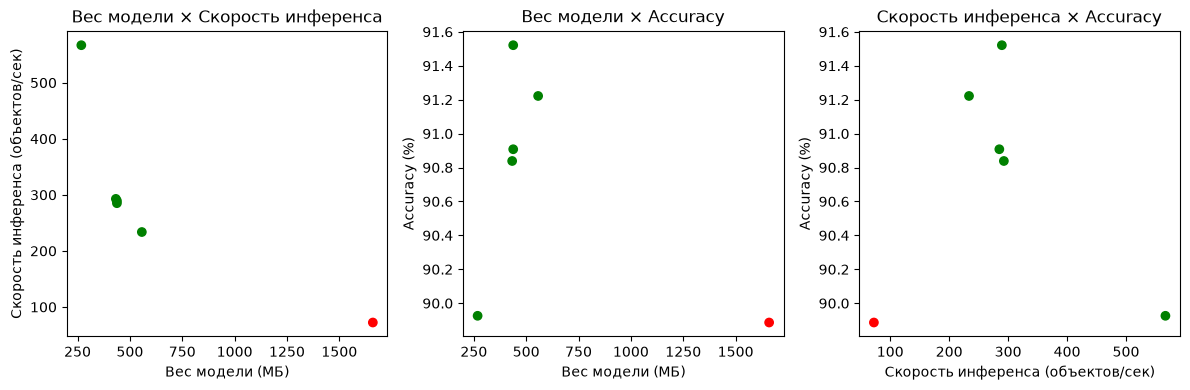

In [104]:
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from itertools import combinations

metrics_res["accuracy_percentage"] = metrics_res["accuracy"] * 100

params = [
    ("Вес модели", "weight_mb", "МБ"),
    ("Скорость инференса", "samples_per_second", "объектов/сек"),
    ("Accuracy", "accuracy_percentage", "%"),
]

combos = len(params) * (len(params)-1) // 2 # 3
_, axs = plt.subplots(1, combos, figsize=(4 * combos, 4))
axs: list[Axes]

for ax, plot_params in zip(axs, combinations(params, 2)):
    ax.scatter(
        *[metrics_res[item[1]] for item in plot_params],
        c = metrics_res.index.map(lambda v: "red" if v == "Tomor0720/deberta-large-finetuned-qqp" else "green")
    )
    title = f"{plot_params[0][0]} $\\times$ {plot_params[1][0]}"
    ax.set_title(title)
    xlabel, ylabel = [f"{item[0]} ({item[2]})" for item in plot_params]
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
plt.tight_layout()

> Видим что в основном есть довольно ожидаемая корреляция $\text{accuracy} \sim \text{weight} \sim 1 / \text{rate}$. Обнаружился интересный выброс: `Tomor0720/deberta-large-finetuned-qqp`, у этой модели точность даже ниже чем у другой модели того же автора на более маленькой модели. Лучше всего по точности проявляет себя модель `rajiv003/ernie-finetuned-qqp`. При этом по скорости инференса почти все модели сравнимы. Заметно быстрее отрабатывает модель `assemblyai/distilbert-base-uncased-qqp`: хоть _accuracy_ там на $1,6$ процентных пунктов ниже чем у лучшей модели, её скорость в два раза быстрее.

### Finding Duplicates (1 point)

Finally, it is time to use your model to find duplicate questions.
Please implement a function that takes a question and finds top-5 potential duplicates in the training set. For now, it is fine if your function is slow, as long as it yields correct results.

Showcase how your function works with at least 5 examples.

### Task 3 (1 point):
- Implement function for finding duplicates
- Test it on several examples (at least 5)
- Check suggested duplicates and make a conclusion about model correctness

In [119]:
model_name = "rajiv003/ernie-finetuned-qqp"
tokenizer = transformers.AutoTokenizer.from_pretrained(model_name)
model: transformers.BertForSequenceClassification = transformers.AutoModelForSequenceClassification.from_pretrained(model_name)
model.to(DEVICE)

def preprocess_function(examples):
    result = tokenizer(
        examples["text1"],
        examples["text2"],
        padding="max_length",
        max_length=MAX_LENGTH,
        truncation=True,
    )
    result["label"] = examples["label"]
    return result

qqp_preprocessed = qqp.map(preprocess_function, batched=True, desc=f"Предобработка данных для модели {model.name_or_path}")

# print(*qqp_preprocessed.keys())
train_set = qqp_preprocessed["train"]
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=32, num_workers=8, shuffle=False, collate_fn=transformers.default_data_collator
)

final_pred_labels = torch.zeros((0), device=DEVICE)

with torch.no_grad():
    for batch in tqdm(train_loader, f"Предсказание меток"):
        predicted: torch.Tensor = model(
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
            token_type_ids=batch["token_type_ids"].to(DEVICE),
        ).logits
        pred_labels = torch.argmax(predicted, dim=1)
        final_pred_labels = torch.concat([final_pred_labels, pred_labels])

final_pred_labels[:50]

Предсказание меток: 100%|██████████| 11371/11371 [20:33<00:00,  9.22it/s]


tensor([0., 1., 0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0.,
        1., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0.,
        1., 0., 1., 0., 0., 1., 0., 1., 0., 0., 0., 1., 0., 0.],
       device='cuda:0')

In [121]:
for idx in range(10):
    item = qqp["train"][idx]
    print("Text 1:", item["text1"])
    print("Text 2:", item["text2"])
    print("True label:", item["label_text"])
    print("Predicted label:", "duplicate" if final_pred_labels[idx].item() else "not duplicate")
    print()

Text 1: How is the life of a math student? Could you describe your own experiences?
Text 2: Which level of prepration is enough for the exam jlpt5?
True label: not duplicate
Predicted label: not duplicate

Text 1: How do I control my horny emotions?
Text 2: How do you control your horniness?
True label: duplicate
Predicted label: duplicate

Text 1: What causes stool color to change to yellow?
Text 2: What can cause stool to come out as little balls?
True label: not duplicate
Predicted label: not duplicate

Text 1: What can one do after MBBS?
Text 2: What do i do after my MBBS ?
True label: duplicate
Predicted label: duplicate

Text 1: Where can I find a power outlet for my laptop at Melbourne Airport?
Text 2: Would a second airport in Sydney, Australia be needed if a high-speed rail link was created between Melbourne and Sydney?
True label: not duplicate
Predicted label: not duplicate

Text 1: How not to feel guilty since I am Muslim and I'm conscious we won't have sex together?
Text 2

> Вывод крайне положительный: модель молодец :)

### Bonus: Finding Duplicates Faster (0.5 point)

Try to find a way to run the function faster than just passing over all questions in a loop. For isntance, you can form a short-list of potential candidates using a cheaper method, and then run your tranformer on that short list. If you opted for this solution, please keep both the original implementation and the optimized one - and explain briefly what is the difference there.

### Task 4 (Bonus, 0.5 point):
- Speed up your implementation from "Finding Duplicates" part
- Capture both old and new implementation work time
- Describe your approach

In [ ]:
<A whole lot of YOUR CODE HERE>

### Bonus: Finding Duplicates in Old-Fashioned way (1.5 points)

In this bonus task you are supposed to use pretrained embeddings (word2vec, GloVe or fasttext) for solving the duplicates problem.

### Task 5 (Bonus, 1.5 points):
- Solve Finding Duplicates problem using mentioned embeddings
- Compare old-fashioned solution to previous ones (quality, speed, etc.)
- Make a small report (up to 5 steps, results and conclusions) on work done in this part

In [ ]:
<A whole lot of YOUR CODE HERE>